In [1]:
%reload_ext autoreload
%autoreload 2

In [ ]:

import torch

from topoflow.data.datasets import CrossDocked
from topoflow.data.dataloader import DataLoaderSampleable
from topoflow.utils.visualization import visualize_data

import matplotlib.pyplot as plt

from topoflow.utils.metrics import qed_scorer, logp_scorer, sas_scorer
from topoflow.utils.molecules import data_to_rdmol
import topoflow.utils.constants as constants

atom_decoder = constants.dataset_params['crossdock_full']['atom_decoder']

In [18]:
dataset = CrossDocked(root='../data/CrossDocked', split='train')
norm_params = dataset.norm_params

Processing...


Processed data will be saved to: ../data/CrossDocked/processed
Loading data split from: ../data/CrossDocked/raw/split_by_name.pt
Data split loaded successfully. Keys: ['train', 'test']

Processing 'train' split...


#failed: 0: 100%|██████████| 1/1 [00:00<00:00, 46.81it/s]


Processing train set took 0.00 minutes
Failed samples in train split: 0

Processing 'test' split...


#failed: 1:   7%|▋         | 7/100 [00:00<00:01, 67.12it/s]

...

#failed: 0: 100%|██████████| 1/1 [00:00<00:00, 35.70it/s]


Processing val set took 0.00 minutes
Failed samples in val split: 0

--- Summary of Failed Samples ---
Failed: PDB/SDF: CCPR_YEAST_69_361_0/1a2g_A_rec_4jmv_1ly_lig_tt_min_0_pocket10.pdb, CCPR_YEAST_69_361_0/1a2g_A_rec_4jmv_1ly_lig_tt_min_0.sdf - Reason: Processing returned None
Failed: PDB/SDF: PPIA_HUMAN_1_165_0/2rma_A_rec_3rdd_ea4_lig_tt_docked_0_pocket10.pdb, PPIA_HUMAN_1_165_0/2rma_A_rec_3rdd_ea4_lig_tt_docked_0.sdf - Reason: Processing returned None
Loading data from ../data/CrossDocked/processed/train.npz for split 'train'...
Normalizing coordinates for ligands and pockets in training split...
Original histogram: 1/10530 bins filled
Smoothed histogram: 25/10530 bins filled
Reconstructing 1 samples from train.npz...


100%|██████████| 1/1 [00:00<00:00, 273.85it/s]

Finished reconstructing samples for 'train'. Total samples for this split: 1
Collating 1 individual Data objects for split 'train'...
Saving collated data to ../data/CrossDocked/processed/train_crossdocked_pyg.pt...
Processed dataset saved successfully.
Loaded dataset from ../data/CrossDocked/processed/train_crossdocked_pyg.pt.



Done!


/home/marco/miniforge3/envs/topoflow/lib/python3.10/site-packages/torch_geometric/data/in_memory_dataset.py:300: UserWarning: It is not recommended to directly access the internal storage format `data` of an 'InMemoryDataset'. If you are absolutely certain what you are doing, access the internal storage via `InMemoryDataset._data` instead to suppress this warning. Alternatively, you can access stacked individual attributes of every graph via `dataset.{attr_name}`.
  warnings.warn(msg)


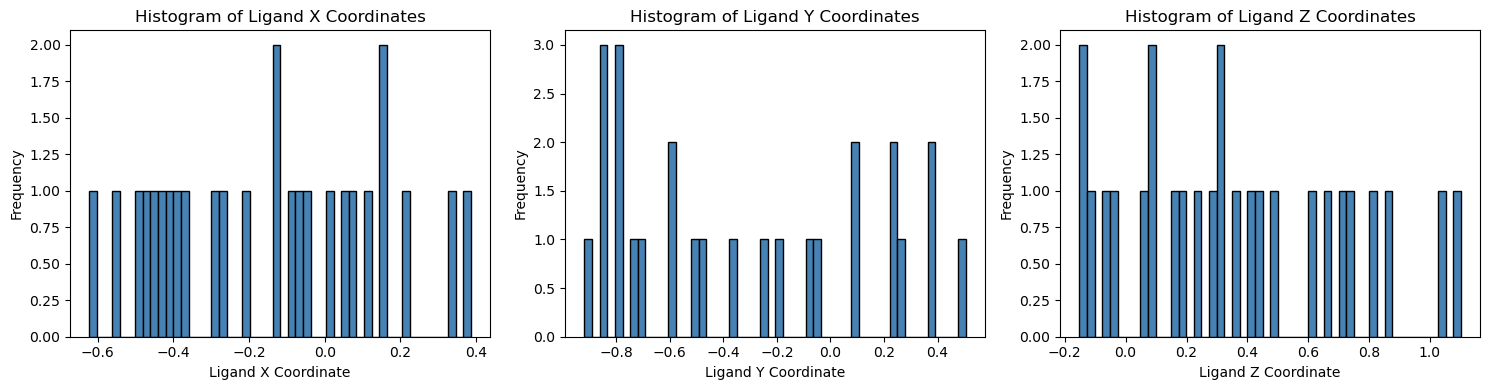

In [19]:
import matplotlib.pyplot as plt

# Get ligand coordinates as numpy array
data = dataset.data
x_lig = data.x_lig.cpu().numpy()  # shape: [num_atoms, 3]

# Set up side-by-side subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes = axes.flatten()
labels = ['X', 'Y', 'Z']

for i in range(3):
    axes[i].hist(x_lig[:, i], bins=50, color='steelblue', edgecolor='black')
    axes[i].set_xlabel(f'Ligand {labels[i]} Coordinate')
    axes[i].set_ylabel('Frequency')
    axes[i].set_title(f'Histogram of Ligand {labels[i]} Coordinates')

plt.tight_layout()
plt.show()


In [20]:
for data in dataset:
    print(data)
    break
print(len(dataset))

Data(h_lig=[26, 11], x_lig=[26, 3], batch_lig=[26], h_pocket=[389, 11], x_pocket=[389, 3], batch_pocket=[389])
1


In [21]:
print(dataset.data)

Data(h_lig=[26, 11], x_lig=[26, 3], batch_lig=[26], h_pocket=[389, 11], x_pocket=[389, 3], batch_pocket=[389])


In [22]:
image_path = "outputs/data_0.png"
session_path = "outputs/session_0.pse"
visualize_data(data, image_path=image_path, session_path=session_path, dataset_name='crossdock_full', norm_params=norm_params)

Successfully saved ligand to: temp_ligand.sdf
Successfully saved pocket to: temp_pocket.pdb
Loading protein from: temp_pocket.pdb as 'protein'
Loading ligand from: temp_ligand.sdf as 'ligand'
Applying custom ligand coloring based on dataset_param...
Image saved to: outputs/data_0.png
Session saved to: outputs/session_0.pse

PyMOL visualization setup complete. You can now interact with the window.


In [15]:
sampleable_dataloader = DataLoaderSampleable(dataset, batch_size=100, shuffle=True, num_workers=4)
print(len(sampleable_dataloader))

/home/marco/miniforge3/envs/topoflow/lib/python3.10/site-packages/torch_geometric/deprecation.py:26: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  warnings.warn(out)


10


In [17]:
batch = sampleable_dataloader.sample()
print(batch)
print(torch.max(batch[1]))

(tensor([[-0.3644,  0.4031,  0.7504,  ...,  0.0000,  0.0000,  0.0000],
        [-0.6897,  0.5181,  0.4212,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.3043,  0.5424,  0.2112,  ...,  0.0000,  0.0000,  0.0000],
        ...,
        [-0.6923, -1.9609, -0.9840,  ...,  0.0000,  0.0000,  0.0000],
        [-0.5197, -2.0763, -1.0057,  ...,  0.0000,  0.0000,  0.0000],
        [-0.8789, -2.0447, -0.9449,  ...,  0.0000,  0.0000,  0.0000]]), tensor([ 0,  0,  0,  ..., 99, 99, 99]), tensor([ 0,  0,  0,  ..., 99, 99, 99]), 100)
tensor(99)


In [25]:
qed_scores = []
logp_scores = []
sas_scores = []

for i, data in enumerate(dataset):
    mol = data_to_rdmol(data, atom_decoder=atom_decoder, sanitize=True)[0]
    qed = qed_scorer(mol)
    logp = logp_scorer(mol)
    sas = sas_scorer(mol)
    if qed is not None:
        qed_scores.append(qed)
    if logp is not None:
        logp_scores.append(logp)
    if sas is not None:
        sas_scores.append(sas)

*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is Generated by make_mol_openbabel)

*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is Generated by make_mol_openbabel)

*** Open Babel Error  in TetStereoToWedgeHash
  Failed to set stereochemistry as unable to find an available bond
*** Open Babel Error  in TetStereoToWedgeHash
  Failed to set stereochemistry as unable to find an available bond
[14:13:23] Both bonds on one end of an atropisomer are on the same side - atoms are: 14 13
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is Generated by make_mol_openbabel)

*** Open Babel Error  in TetStereoToWedgeHash
  Failed to set stereochemistry as unable to find an available bond
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBo

Sanitization failed for batch 0: Explicit valence for atom # 19 N, 4, is greater than permitted
Error calculating metric: Explicit valence for atom # 19 N, 4, is greater than permitted
Error calculating metric: Pre-condition Violation
	RingInfo not initialized
	Violation occurred on line 52 in file Code/GraphMol/RingInfo.cpp
	Failed Expression: df_init
	RDKIT: 2025.03.3
	BOOST: 



*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is Generated by make_mol_openbabel)

*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is Generated by make_mol_openbabel)

[14:13:24] Both bonds on one end of an atropisomer are on the same side - atoms are: 20 21
[14:13:24] Both bonds on one end of an atropisomer are on the same side - atoms are: 14 16
[14:13:24] Explicit valence for atom # 30 N, 4, is greater than permitted
[14:13:24] Explicit valence for atom # 30 N, 4, is greater than permitted
[14:13:24] 

****
Pre-condition Violation
RingInfo not initialized
Violation occurred on line 52 in file /home/conda/feedstock_root/build_artifacts/rdkit-meta_1749209499913/work/Code/GraphMol/RingInfo.cpp
Failed Expression: df_init
----------
Stacktrace:
 0# Invar::Invariant::toString[abi:cxx11]() const in /home/marco/miniforge3/envs/topoflow/lib/python3.10/

Sanitization failed for batch 0: Explicit valence for atom # 30 N, 4, is greater than permitted
Error calculating metric: Explicit valence for atom # 30 N, 4, is greater than permitted
Error calculating metric: Pre-condition Violation
	RingInfo not initialized
	Violation occurred on line 52 in file Code/GraphMol/RingInfo.cpp
	Failed Expression: df_init
	RDKIT: 2025.03.3
	BOOST: 

Sanitization failed for batch 0: Explicit valence for atom # 25 N, 4, is greater than permitted
Error calculating metric: Explicit valence for atom # 25 N, 4, is greater than permitted
Error calculating metric: Pre-condition Violation
	RingInfo not initialized
	Violation occurred on line 52 in file Code/GraphMol/RingInfo.cpp
	Failed Expression: df_init
	RDKIT: 2025.03.3
	BOOST: 



[14:13:24] Both bonds on one end of an atropisomer are on the same side - atoms are: 9 4
[14:13:24] Both bonds on one end of an atropisomer are on the same side - atoms are: 9 25
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is Generated by make_mol_openbabel)

*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is Generated by make_mol_openbabel)

[14:13:24] Both bonds on one end of an atropisomer are on the same side - atoms are: 0 18
[14:13:24] Both bonds on one end of an atropisomer are on the same side - atoms are: 0 17
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is Generated by make_mol_openbabel)

[14:13:24] Both bonds on one end of an atropisomer are on the same side - atoms are: 4 9
[14:13:24] Both bonds on one end of an atropisomer are on the same side - atoms are: 5 

...

*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is Generated by make_mol_openbabel)

[14:13:27] Both bonds on one end of an atropisomer are on the same side - atoms are: 28 22
[14:13:27] Both bonds on one end of an atropisomer are on the same side - atoms are: 25 26
[14:13:27] Both bonds on one end of an atropisomer are on the same side - atoms are: 15 14
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is Generated by make_mol_openbabel)

*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is Generated by make_mol_openbabel)

[14:13:27] Both bonds on one end of an atropisomer are on the same side - atoms are: 16 17
[14:13:27] Both bonds on one end of an atropisomer are on the same side - atoms are: 13 9
[14:13:27] Both bonds on one end of an atropisomer are on the same side - atoms a

Sanitization failed for batch 0: Explicit valence for atom # 7 N, 4, is greater than permitted
Error calculating metric: Explicit valence for atom # 7 N, 4, is greater than permitted
Error calculating metric: Pre-condition Violation
	RingInfo not initialized
	Violation occurred on line 52 in file Code/GraphMol/RingInfo.cpp
	Failed Expression: df_init
	RDKIT: 2025.03.3
	BOOST: 



*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is Generated by make_mol_openbabel)

[14:13:27] Both bonds on one end of an atropisomer are on the same side - atoms are: 16 20
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is Generated by make_mol_openbabel)

[14:13:28] Both bonds on one end of an atropisomer are on the same side - atoms are: 18 19
[14:13:28] Both bonds on one end of an atropisomer are on the same side - atoms are: 17 19
[14:13:28] Both bonds on one end of an atropisomer are on the same side - atoms are: 1 18
[14:13:28] Both bonds on one end of an atropisomer are on the same side - atoms are: 22 23
[14:13:28] Both bonds on one end of an atropisomer are on the same side - atoms are: 27 26
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is Generated by make_mol_op

Sanitization failed for batch 0: Explicit valence for atom # 26 N, 4, is greater than permitted
Error calculating metric: Explicit valence for atom # 26 N, 4, is greater than permitted
Error calculating metric: Pre-condition Violation
	RingInfo not initialized
	Violation occurred on line 52 in file Code/GraphMol/RingInfo.cpp
	Failed Expression: df_init
	RDKIT: 2025.03.3
	BOOST: 

Sanitization failed for batch 0: Explicit valence for atom # 7 N, 4, is greater than permitted
Error calculating metric: Explicit valence for atom # 7 N, 4, is greater than permitted
Error calculating metric: Pre-condition Violation
	RingInfo not initialized
	Violation occurred on line 52 in file Code/GraphMol/RingInfo.cpp
	Failed Expression: df_init
	RDKIT: 2025.03.3
	BOOST: 

Sanitization failed for batch 0: Explicit valence for atom # 15 N, 4, is greater than permitted
Error calculating metric: Explicit valence for atom # 15 N, 4, is greater than permitted
Error calculating metric: Pre-condition Violation
	

[14:13:28] Both bonds on one end of an atropisomer are on the same side - atoms are: 11 10
[14:13:28] Both bonds on one end of an atropisomer are on the same side - atoms are: 8 10
[14:13:28] Both bonds on one end of an atropisomer are on the same side - atoms are: 5 8
[14:13:28] Explicit valence for atom # 7 N, 4, is greater than permitted
[14:13:28] Explicit valence for atom # 7 N, 4, is greater than permitted
[14:13:28] 

****
Pre-condition Violation
RingInfo not initialized
Violation occurred on line 52 in file /home/conda/feedstock_root/build_artifacts/rdkit-meta_1749209499913/work/Code/GraphMol/RingInfo.cpp
Failed Expression: df_init
----------
Stacktrace:
 0# Invar::Invariant::toString[abi:cxx11]() const in /home/marco/miniforge3/envs/topoflow/lib/python3.10/site-packages/rdkit/../../../libRDKitRDGeneral.so.1
 1# Invar::operator<<(std::ostream&, Invar::Invariant const&) in /home/marco/miniforge3/envs/topoflow/lib/python3.10/site-packages/rdkit/../../../libRDKitRDGeneral.so.1
 2#

In [26]:
qed_scores = torch.tensor(qed_scores)
logp_scores = torch.tensor(logp_scores)
sas_scores = torch.tensor(sas_scores)

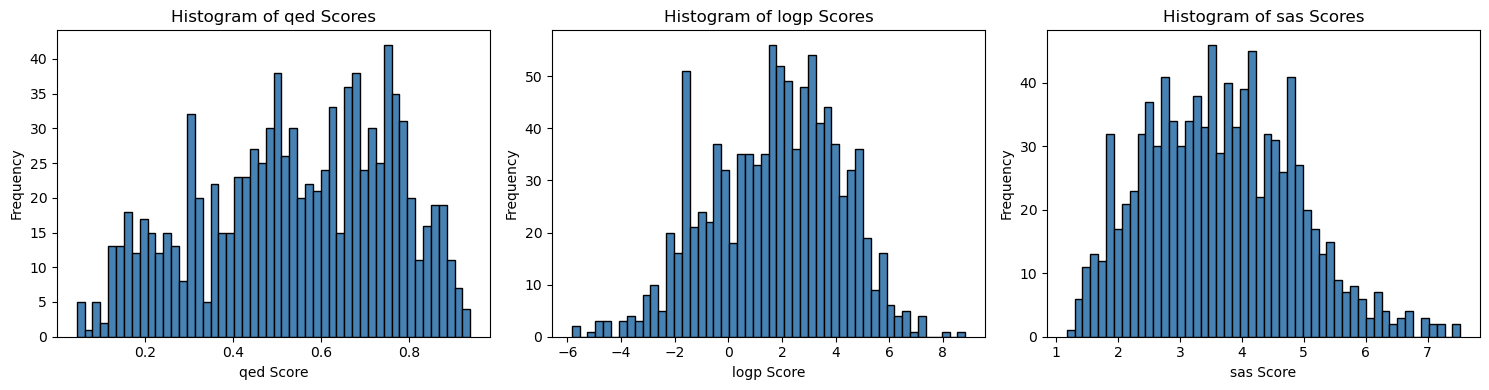

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes = axes.flatten()
labels = ['qed', 'logp', 'sas']

for i in range(3):
    axes[i].hist(qed_scores if i == 0 else logp_scores if i == 1 else sas_scores,
                 bins=50, color='steelblue', edgecolor='black')
    axes[i].set_xlabel(f'{labels[i]} Score')
    axes[i].set_ylabel('Frequency')
    axes[i].set_title(f'Histogram of {labels[i]} Scores')
    
plt.tight_layout()
plt.show()